# Exercises XP Ninja: Advanced CNN Projects

This guided notebook follows the exercises on the platform. Cells marked **PREFILLED** are for execution only. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

Learning points appear only for key concepts to support intuition or transfer to other AI topics.

## What you will learn
- Advanced CNN architectures and techniques
- Handling imbalanced datasets
- Transfer learning and fine tuning
- Model interpretability and visualization
- Building a robust classification pipeline

## What you will create
Five CNN based projects. Each addresses a specific challenge.

## How I run this notebook
I run it in Google Colab from top to bottom (a GPU runtime is faster, but it also runs on a CPU). Everything is downloaded by the code: CIFAR-10, the MobileNetV2 weights and the TensorFlow flower photos for Exercise 5. LIME is installed by the code if it is missing. Seeds are fixed so the numbers can be repeated (on a GPU the last decimals can move a little).

I ran everything on a CPU, so some runs are short on purpose and I say so where it happens. In Exercise 1 I use 20,000 training images at their native 32x32 size, and in Exercise 3 a 5,000 image subset, with 3 epochs for each fine-tuning run.

## Common setup

**As stated in the exercises**  
You will build and evaluate CNN models under different constraints.

**PREFILLED**  
Imports, versions, seed control, and a simple plot helper. Execute this first.

In [1]:
# PREFILLED: just execute
import os, time, math, json, random, itertools
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

def plot_history(history, title="Training curves"):
    plt.figure(figsize=(6,4))
    if "accuracy" in history.history: plt.plot(history.history["accuracy"], label="acc")
    if "val_accuracy" in history.history: plt.plot(history.history["val_accuracy"], label="val_acc")
    plt.title(title); plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.tight_layout(); plt.show()
    plt.figure(figsize=(6,4))
    if "loss" in history.history: plt.plot(history.history["loss"], label="loss")
    if "val_loss" in history.history: plt.plot(history.history["val_loss"], label="val_loss")
    plt.title(title); plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.tight_layout(); plt.show()

TensorFlow: 2.21.0


# Exercise 1: Multi label image classification

**As stated in the exercises**  
Choose a dataset where each image can have multiple labels. Build a CNN with a sigmoid output and use binary cross entropy. Handle dependencies between labels by experimenting with approaches such as recurrent layers or label embeddings.

### 1.1 Dataset interface

**PREFILLED**  
Expected CSV format: `filepath,labels` where `labels` is a `|` separated list. The code below parses the CSV and builds a multi hot vector per image based on the discovered vocabulary. If no CSV is provided, a toy multi label dataset is synthesized from CIFAR 10 using attributes such as `animal` and `vehicle` for demonstration.

In [2]:
# PREFILLED: just execute
import pandas as pd

def build_multilabel_from_csv(csv_path, root_dir):
    df = pd.read_csv(csv_path)
    df['filepath'] = df['filepath'].astype(str)
    df['labels'] = df['labels'].astype(str)
    vocab = sorted(set(itertools.chain.from_iterable([s.split('|') for s in df['labels']])))
    tok = {t:i for i,t in enumerate(vocab)}
    y = np.zeros((len(df), len(vocab)), dtype=np.float32)
    for i, s in enumerate(df['labels']):
        for t in s.split('|'):
            y[i, tok[t]] = 1.0
    x_paths = [str(Path(root_dir)/p) for p in df['filepath']]
    return x_paths, y, vocab

def load_image(path, size=(160,160)):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, size)
    return img

def make_dataset_multilabel(x_paths, y, batch=32, shuffle=True, aug=False, size=(160,160)):
    x = tf.constant(x_paths)
    y = tf.constant(y, dtype=tf.float32)
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    def _map(p, lab):
        im = load_image(p, size)
        if aug:
            im = tf.image.random_flip_left_right(im)
            im = tf.image.random_brightness(im, 0.1)
            im = tf.image.random_contrast(im, 0.9, 1.1)
        return im, lab
    if shuffle:
        ds = ds.shuffle(buffer_size=min(10000, len(x_paths)))
    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE).batch(batch).prefetch(tf.data.AUTOTUNE)
    return ds

# Try to locate a CSV next to this notebook
CSV_CANDIDATES = [p for p in Path('.').glob('*.csv')]
if CSV_CANDIDATES:
    print("Found CSV:", CSV_CANDIDATES[0])
else:
    print("No CSV found. A toy dataset will be used if you run the fallback cell below.")

No CSV found. A toy dataset will be used if you run the fallback cell below.


**How my multi-label set is built (honest note).** I don't have a real multi-label CSV, so I use the prefilled fallback. Every CIFAR-10 image gets **two labels derived from its class**: what it is (`animal` / `vehicle`) and where or how it lives (`air`, `land`, `water`, `pet`, `wild`), for 7 labels in total. Because the labels come from the class, they are fully dependent on each other. For example `pet` always comes with `animal`, and `water` always comes with `vehicle`. That makes it a good set for testing the label-dependency part, but it is easier than real multi-label data, where any combination can happen. Horse is labelled `pet` in the template (domesticated), and I kept that.

To keep it fast on a CPU, I changed only how the prefilled cell is called: 20,000 training images at their native 32x32 size instead of all 50,000 resized to 160x160. Upscaling a 32x32 image adds no new information.

In [3]:
# PREFILLED: just execute: toy multi label fallback using CIFAR 10
from tensorflow.keras.datasets import cifar10
(x_tr_c10, y_tr_c10), (x_te_c10, y_te_c10) = cifar10.load_data()
y_tr_c10 = y_tr_c10.ravel(); y_te_c10 = y_te_c10.ravel()
# attributes: animal vs vehicle, pet vs wild
attr = {
    0: ("vehicle","air"),     # airplane
    1: ("vehicle","land"),    # automobile
    2: ("animal","wild"),     # bird
    3: ("animal","pet"),      # cat
    4: ("animal","wild"),     # deer
    5: ("animal","pet"),      # dog
    6: ("animal","wild"),     # frog
    7: ("animal","pet"),      # horse as non pet but domesticated
    8: ("vehicle","water"),   # ship
    9: ("vehicle","land"),    # truck
}
vocab = sorted(list(set(itertools.chain.from_iterable(attr.values()))))
tok = {t:i for i,t in enumerate(vocab)}

def to_multi_hot(y):
    out = np.zeros((len(y), len(vocab)), dtype=np.float32)
    for i,c in enumerate(y):
        a,b = attr[int(c)]
        out[i, tok[a]] = 1.0
        out[i, tok[b]] = 1.0
    return out

# my change: a 20,000 image subset at native 32x32 so it runs on a CPU
ML_SIZE = (32, 32)
ml_idx = np.random.RandomState(0).choice(len(x_tr_c10), 20000, replace=False)
x_tr_c10, y_tr_c10 = x_tr_c10[ml_idx], y_tr_c10[ml_idx]

y_tr_ml = to_multi_hot(y_tr_c10)
y_te_ml = to_multi_hot(y_te_c10)

def ds_from_numpy(x, y, size=(160,160), batch=64, aug=False):
    x = tf.convert_to_tensor(x)
    y = tf.convert_to_tensor(y, dtype=tf.float32)
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    def _map(im, lab):
        im = tf.image.convert_image_dtype(im, tf.float32)
        im = tf.image.resize(im, size)
        if aug:
            im = tf.image.random_flip_left_right(im)
            im = tf.image.random_brightness(im, 0.1)
        return im, lab
    return ds.shuffle(5000).map(_map, num_parallel_calls=tf.data.AUTOTUNE).batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds_ml = ds_from_numpy(x_tr_c10, y_tr_ml, size=ML_SIZE, aug=True)
val_ds_ml   = ds_from_numpy(x_te_c10, y_te_ml, size=ML_SIZE, aug=False)
print("Toy multi label dataset ready. Labels:", vocab)
print("Label combinations that exist:", sorted(set(attr.values())))

Toy multi label dataset ready. Labels: ['air', 'animal', 'land', 'pet', 'vehicle', 'water', 'wild']
Label combinations that exist: [('animal', 'pet'), ('animal', 'wild'), ('vehicle', 'air'), ('vehicle', 'land'), ('vehicle', 'water')]


### 1.2 Build a multi label CNN

**To-Do:** Create a CNN that outputs `len(vocab)` logits with sigmoid activation. Compile with `binary_crossentropy`. Train on your dataset and report micro and macro F1 on the validation set. Save the list of labels you used.

Epoch 1/10


313/313 - 6s - 21ms/step - accuracy: 0.6189 - loss: 0.3548 - val_accuracy: 0.5781 - val_loss: 0.3112


Epoch 2/10


313/313 - 5s - 17ms/step - accuracy: 0.6505 - loss: 0.2716 - val_accuracy: 0.6738 - val_loss: 0.2477


Epoch 3/10


313/313 - 5s - 16ms/step - accuracy: 0.6581 - loss: 0.2457 - val_accuracy: 0.6500 - val_loss: 0.2269


... (10 outputs left out)

Epoch 9/10


313/313 - 4s - 13ms/step - accuracy: 0.6686 - loss: 0.1689 - val_accuracy: 0.6763 - val_loss: 0.1728


Epoch 10/10


313/313 - 5s - 15ms/step - accuracy: 0.6653 - loss: 0.1616 - val_accuracy: 0.6793 - val_loss: 0.1708


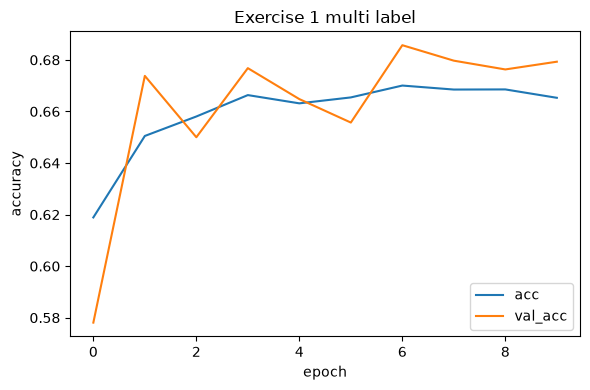

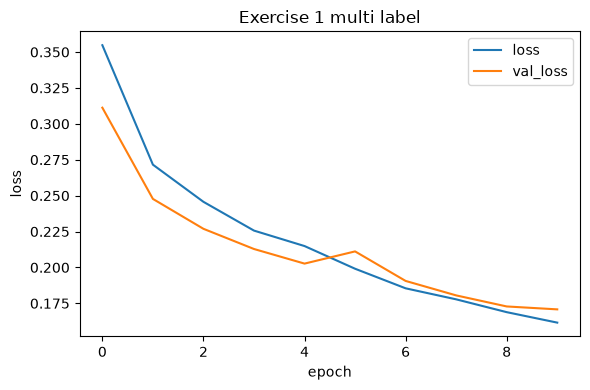

labels saved: ['air', 'animal', 'land', 'pet', 'vehicle', 'water', 'wild']


In [4]:
# To-Do: define and train the multi label model
def ml_trunk(inputs):
    # small CNN feature extractor, shared by both multi-label models
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    return layers.Dense(128, activation="relu")(x)

tf.keras.utils.set_random_seed(42)
inputs = layers.Input(shape=(*ML_SIZE, 3))
x = ml_trunk(inputs)
outputs = layers.Dense(len(vocab), activation="sigmoid")(x)   # one independent yes/no per label
model_ml = models.Model(inputs, outputs)
model_ml.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
h_ml = model_ml.fit(train_ds_ml, validation_data=val_ds_ml, epochs=10, verbose=2)
plot_history(h_ml, title="Exercise 1 multi label")

# save the label list next to the model
json.dump(vocab, open("multilabel_vocab.json", "w"))
print("labels saved:", vocab)

In [5]:
# To-Do: compute micro and macro F1
from sklearn.metrics import f1_score

valid_sets = {frozenset(v) for v in attr.values()}   # label pairs that can really happen

def ml_scores(model, name, threshold=0.5):
    y_true, y_prob = [], []
    for xb, yb in val_ds_ml:
        y_true.append(yb.numpy()); y_prob.append(model.predict(xb, verbose=0))
    y_true = np.concatenate(y_true); y_prob = np.concatenate(y_prob)
    y_pred = (y_prob >= threshold).astype(int)
    pred_sets = [frozenset(np.array(vocab)[row == 1]) for row in y_pred]
    res = {"model": name,
           "f1_micro": round(f1_score(y_true.ravel(), y_pred.ravel(), average="micro"), 4),
           "f1_macro": round(f1_score(y_true, y_pred, average="macro"), 4),
           "exact_match": round(float((y_pred == y_true).all(axis=1).mean()), 4),
           "impossible_combos": round(float(np.mean([s not in valid_sets for s in pred_sets])), 4)}
    return res, y_true, y_prob

res_ml, y_true_ml, y_prob_ml = ml_scores(model_ml, "independent sigmoids")
print("F1 micro:", res_ml["f1_micro"])
print("F1 macro:", res_ml["f1_macro"])
print(res_ml)

F1 micro: 0.93
F1 macro: 0.8453
{'model': 'independent sigmoids', 'f1_micro': 0.93, 'f1_macro': 0.8453, 'exact_match': 0.7674, 'impossible_combos': 0.0892}


### 1.3 Capture label dependencies

**To-Do:** Add a simple label dependency module. Example options: a Dense layer on logits to allow interaction, a small GRU over label dimension, or a learned label embedding with self attention. Train and compare F1 to the base model.

I try two simple ways to use the label dependencies:
1. **A dependency layer.** The model makes a first guess for all 7 labels, then a small Dense layer looks at all 7 guesses together and corrects the logits. This lets it learn rules like "pet means animal".
2. **Decoding only valid combinations.** At prediction time I score each label pair that really exists and keep the most likely one. It needs no training at all.

In [6]:
# 1) dependency layer on top of the label logits
tf.keras.utils.set_random_seed(42)
inputs = layers.Input(shape=(*ML_SIZE, 3))
feat = ml_trunk(inputs)
logits = layers.Dense(len(vocab), name="first_guess")(feat)          # independent logits
probs1 = layers.Activation("sigmoid")(logits)
mix = layers.Dense(32, activation="relu")(probs1)                    # looks at all labels together
correction = layers.Dense(len(vocab), name="label_interaction")(mix)
outputs = layers.Activation("sigmoid")(layers.Add()([logits, correction]))
model_dep = models.Model(inputs, outputs)
model_dep.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
h_dep = model_dep.fit(train_ds_ml, validation_data=val_ds_ml, epochs=10, verbose=2)
res_dep, _, _ = ml_scores(model_dep, "with dependency layer")

# 2) choose the most likely valid pair from the independent model's probabilities
combos = sorted(valid_sets, key=sorted)
combo_mat = np.array([[1 if t in c else 0 for t in vocab] for c in combos])
eps = 1e-7
log_p = np.log(y_prob_ml + eps); log_q = np.log(1 - y_prob_ml + eps)
scores = log_p @ combo_mat.T + log_q @ (1 - combo_mat).T   # log-likelihood of each valid pair
y_pred_dec = combo_mat[scores.argmax(axis=1)]
res_dec = {"model": "independent + valid-pair decoding",
           "f1_micro": round(f1_score(y_true_ml.ravel(), y_pred_dec.ravel(), average="micro"), 4),
           "f1_macro": round(f1_score(y_true_ml, y_pred_dec, average="macro"), 4),
           "exact_match": round(float((y_pred_dec == y_true_ml).all(axis=1).mean()), 4),
           "impossible_combos": 0.0}

import pandas as pd
pd.DataFrame([res_ml, res_dep, res_dec])

Epoch 1/10


313/313 - 6s - 19ms/step - accuracy: 0.6205 - loss: 0.3508 - val_accuracy: 0.6244 - val_loss: 0.2939


Epoch 2/10


313/313 - 5s - 17ms/step - accuracy: 0.6549 - loss: 0.2670 - val_accuracy: 0.6829 - val_loss: 0.2406


Epoch 3/10


313/313 - 5s - 15ms/step - accuracy: 0.6681 - loss: 0.2417 - val_accuracy: 0.5801 - val_loss: 0.2818


... (11 outputs left out)

313/313 - 3s - 10ms/step - accuracy: 0.6640 - loss: 0.1678 - val_accuracy: 0.6610 - val_loss: 0.1738


Epoch 10/10


313/313 - 5s - 16ms/step - accuracy: 0.6651 - loss: 0.1602 - val_accuracy: 0.6985 - val_loss: 0.1866


,model,f1_micro,f1_macro,exact_match,impossible_combos
0,independent sigmoids,0.9300,0.8453,0.7674,0.0892
1,with dependency layer,0.9240,0.8344,0.7591,0.0772
2,independent + valid-pair decoding,0.9288,0.8464,0.8077,0.0000


**What I see:** The independent sigmoid model reaches **micro F1 0.930 and macro F1 0.845**. All 7 labels are correct for 76.7% of the test images, but **8.9% of its predictions are impossible combinations** (for example `animal` + `water`, or only one label). The **dependency layer** lowered the impossible combinations to 7.7%, but F1 did not improve (0.924 / 0.834). Between my two runs these numbers moved by about half a point (the tf.data pipeline is not fully deterministic), so I see no real difference. **Valid-pair decoding** had the clearest effect. Exact match went up from 76.7% to **80.8%**, impossible combinations went to **0%**, and F1 stayed the same (0.929 / 0.846). Because my labels are derived from the class, choosing the best valid pair is really a 5-way classification, which is why it works so well here. Macro F1 is lower than micro F1 because the rarer, harder labels count as much as the easy, frequent ones (`animal` and `vehicle` are on every image). I did not try recurrent layers or label embeddings: with 7 labels that always come in fixed pairs, a GRU over labels would be overkill. On a real multi-label set with many free combinations I would try them. Note: the `accuracy` Keras prints in the training log (about 0.67) is not a useful multi-label metric, so I judge the models by F1 and exact match.

**Learning point**  
Multi label outputs model independent Bernoulli decisions. Explicitly modeling co occurrence can improve calibration and reduce contradictory predictions.

# Exercise 2: Class imbalance handling

**As stated in the exercises**  
Select a dataset with strong class imbalance. Train a CNN and address imbalance with oversampling, undersampling, or weighted loss. Evaluate with precision, recall, F1, and AUC ROC and compare to a baseline.

### 2.1 Simulate imbalance

**PREFILLED**  
We create an imbalanced subset of CIFAR 10 by downsampling one class.

**One change to the prefilled cell:** with `keep_minor = 300` the bird class has 300 images and every other class about 555 (5,000 / 9), which is less than 2:1 and not much of an imbalance. I set `keep_minor = 100`, so birds are outnumbered about 5.5 to 1 (2% of the set). Everything else is the same. I always evaluate on the full, balanced CIFAR-10 test set (1,000 birds out of 10,000).

In [7]:
# PREFILLED: just execute
from tensorflow.keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
y_train = y_train.ravel(); y_test = y_test.ravel()

minor_class = 2  # bird
keep_minor = 100   # was 300; 100 gives a real imbalance (about 5.5:1)
keep_major = 5000

idx_minor = np.where(y_train==minor_class)[0]
idx_major = np.where(y_train!=minor_class)[0]
sel = np.concatenate([np.random.choice(idx_minor, keep_minor, replace=False),
                      np.random.choice(idx_major, keep_major, replace=False)])
np.random.shuffle(sel)
x_imb = x_train[sel]; y_imb = y_train[sel]
print("Imbalanced set:", x_imb.shape, "minority ratio:", (y_imb==minor_class).mean())
print("images per class:", np.bincount(y_imb))

Imbalanced set: (5100, 32, 32, 3) minority ratio: 0.0196078431372549
images per class: [554 536 100 519 568 586 533 574 570 560]


### 2.2 Baseline model and metrics

**To-Do:** Train a baseline CNN on the imbalanced set without any correction. Compute precision, recall, F1 per class and macro average. Plot a normalized confusion matrix.

Epoch 1/10


32/32 - 2s - 52ms/step - accuracy: 0.1792 - loss: 2.1741 - val_accuracy: 0.3343 - val_loss: 1.8976


Epoch 2/10


32/32 - 1s - 23ms/step - accuracy: 0.3650 - loss: 1.7581 - val_accuracy: 0.4225 - val_loss: 1.6645


Epoch 3/10


32/32 - 1s - 24ms/step - accuracy: 0.4176 - loss: 1.5995 - val_accuracy: 0.4637 - val_loss: 1.5335


... (10 outputs left out)

Epoch 9/10


32/32 - 1s - 39ms/step - accuracy: 0.6039 - loss: 1.1112 - val_accuracy: 0.5657 - val_loss: 1.2680


Epoch 10/10


32/32 - 1s - 20ms/step - accuracy: 0.6306 - loss: 1.0575 - val_accuracy: 0.5814 - val_loss: 1.2278


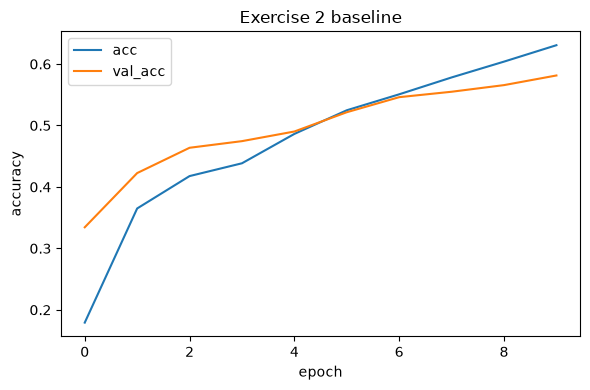

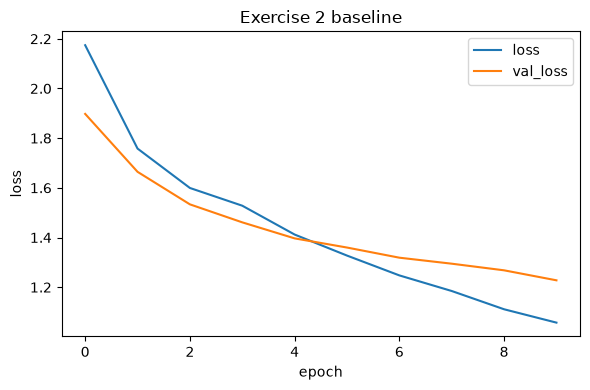

In [8]:
# To-Do: train baseline on x_imb, y_imb
tf.keras.utils.set_random_seed(42)
base = tf.keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
base.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_base = base.fit(x_imb, y_imb, epochs=10, batch_size=128, validation_split=0.2, verbose=2)
plot_history(h_base, title="Exercise 2 baseline")

              precision    recall  f1-score   support

    airplane      0.510     0.645     0.570      1000
  automobile      0.735     0.595     0.657      1000
        bird      0.543     0.025     0.048      1000
         cat      0.416     0.246     0.309      1000
        deer      0.424     0.546     0.477      1000
         dog      0.368     0.694     0.481      1000
        frog      0.754     0.518     0.614      1000
       horse      0.645     0.562     0.601      1000
        ship      0.544     0.792     0.645      1000
       truck      0.593     0.654     0.622      1000

    accuracy                          0.528     10000
   macro avg      0.553     0.528     0.502     10000
weighted avg      0.553     0.528     0.502     10000



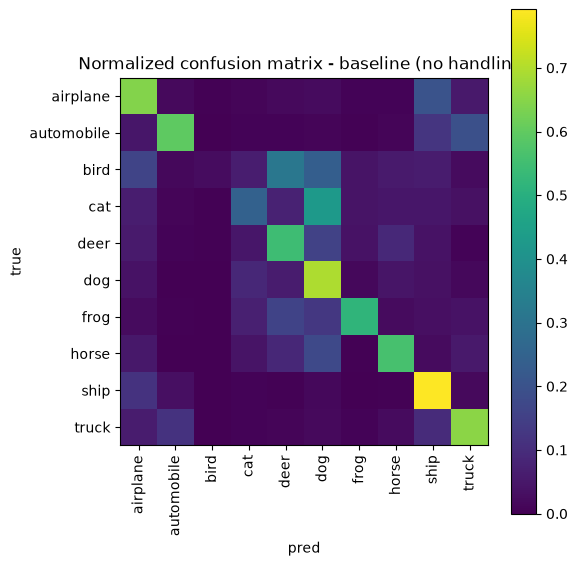

{'run': 'baseline (no handling)', 'accuracy': 0.5277, 'macro_f1': 0.5025, 'bird_precision': 0.5435, 'bird_recall': 0.025, 'bird_f1': 0.0478, 'bird_auc': 0.802, 'macro_auc_ovr': 0.8993}


In [9]:
# To-Do: evaluate baseline with precision, recall, F1, and confusion matrix
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, roc_auc_score
class_names_c10 = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
imb_results = []

def eval_imb(model, name, show=False):
    probs = model.predict(x_test, verbose=0)
    y_pred = probs.argmax(axis=1)
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=list(range(10)), zero_division=0)
    res = {"run": name,
           "accuracy": round(float((y_pred == y_test).mean()), 4),
           "macro_f1": round(float(f.mean()), 4),
           "bird_precision": round(float(p[minor_class]), 4),
           "bird_recall": round(float(r[minor_class]), 4),
           "bird_f1": round(float(f[minor_class]), 4),
           "bird_auc": round(roc_auc_score(y_test == minor_class, probs[:, minor_class]), 4),
           "macro_auc_ovr": round(roc_auc_score(y_test, probs, multi_class="ovr"), 4)}
    imb_results.append(res)
    if show:
        print(classification_report(y_test, y_pred, target_names=class_names_c10, digits=3, zero_division=0))
        cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))
        plt.figure(figsize=(6,6))
        plt.imshow(cm / cm.sum(axis=1, keepdims=True))
        plt.title(f"Normalized confusion matrix - {name}")
        plt.xticks(range(10), class_names_c10, rotation=90); plt.yticks(range(10), class_names_c10)
        plt.xlabel("pred"); plt.ylabel("true")
        plt.colorbar(); plt.tight_layout(); plt.show()
    print(res)
    return res

eval_imb(base, "baseline (no handling)", show=True);

### 2.3 Apply imbalance techniques

**To-Do:** Train three new runs using: class weights, oversampling, and focal loss. Keep the architecture fixed. Compare the per class recall and macro F1.

I also add **undersampling** of the majority classes, because the exercise on the platform asks for it. Every run uses `clone_model(base)`, which gives the same architecture with fresh weights.

In [10]:
# To-Do: class weights
unique, counts = np.unique(y_imb, return_counts=True)
freq = counts / counts.sum()
cw = {int(c): float(1.0 / (len(unique) * f)) for c, f in zip(unique, freq)}   # rare class -> bigger weight
print({class_names_c10[k]: round(v, 2) for k, v in cw.items()})
tf.keras.utils.set_random_seed(42)
base_cw = tf.keras.models.clone_model(base)
base_cw.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_cw = base_cw.fit(x_imb, y_imb, epochs=10, batch_size=128, validation_split=0.2, class_weight=cw, verbose=2)
eval_imb(base_cw, "class weights");

{'airplane': 0.92, 'automobile': 0.95, 'bird': 5.1, 'cat': 0.98, 'deer': 0.9, 'dog': 0.87, 'frog': 0.96, 'horse': 0.89, 'ship': 0.89, 'truck': 0.91}


Epoch 1/10


32/32 - 1s - 44ms/step - accuracy: 0.1409 - loss: 2.2474 - val_accuracy: 0.2706 - val_loss: 2.0648


Epoch 2/10


32/32 - 1s - 18ms/step - accuracy: 0.3196 - loss: 1.8706 - val_accuracy: 0.3324 - val_loss: 1.8044


Epoch 3/10


... (12 outputs left out)

32/32 - 1s - 20ms/step - accuracy: 0.5588 - loss: 1.1845 - val_accuracy: 0.5441 - val_loss: 1.2776


Epoch 10/10


32/32 - 1s - 19ms/step - accuracy: 0.5973 - loss: 1.1079 - val_accuracy: 0.5510 - val_loss: 1.2485


{'run': 'class weights', 'accuracy': 0.5347, 'macro_f1': 0.5318, 'bird_precision': 0.4029, 'bird_recall': 0.334, 'bird_f1': 0.3652, 'bird_auc': 0.81, 'macro_auc_ovr': 0.8997}


In [11]:
# To-Do: oversampling with tf.data
# I sample single images (not whole batches) so each batch mixes birds and other classes.
def ds_from_numpy(x, y, batch=128, aug=True):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    def _map(im, lab):
        im = tf.cast(im, tf.float32)
        if aug:
            im = tf.image.random_flip_left_right(im)   # repeated birds are not exact copies
        return im, lab
    ds = ds.shuffle(len(x)).repeat().map(_map, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE) if batch else ds

ds_minor = ds_from_numpy(x_imb[y_imb==minor_class], y_imb[y_imb==minor_class], batch=None, aug=True)
ds_major = ds_from_numpy(x_imb[y_imb!=minor_class], y_imb[y_imb!=minor_class], batch=None, aug=False)
# 0.1 / 0.9 makes birds about as common as each of the other 9 classes (0.5 / 0.5 would make half of all images birds)
ds_bal = tf.data.Dataset.sample_from_datasets([ds_minor, ds_major], weights=[0.1, 0.9], seed=42).batch(128).prefetch(tf.data.AUTOTUNE)
tf.keras.utils.set_random_seed(42)
base_os = tf.keras.models.clone_model(base)
base_os.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_os = base_os.fit(ds_bal, epochs=10, steps_per_epoch=math.ceil(len(x_imb)/128), verbose=2)
eval_imb(base_os, "oversampling");

Epoch 1/10


40/40 - 2s - 38ms/step - accuracy: 0.2250 - loss: 2.0984


Epoch 2/10


40/40 - 1s - 17ms/step - accuracy: 0.3697 - loss: 1.7123


Epoch 3/10


40/40 - 1s - 16ms/step - accuracy: 0.4346 - loss: 1.5471


... (11 outputs left out)

40/40 - 1s - 16ms/step - accuracy: 0.6098 - loss: 1.0908


Epoch 10/10


40/40 - 1s - 13ms/step - accuracy: 0.6447 - loss: 0.9950


{'run': 'oversampling', 'accuracy': 0.5491, 'macro_f1': 0.54, 'bird_precision': 0.444, 'bird_recall': 0.353, 'bird_f1': 0.3933, 'bird_auc': 0.8341, 'macro_auc_ovr': 0.9107}


In [12]:
# undersampling: keep all 100 birds and only 100 images of every other class
rng = np.random.RandomState(42)
under_idx = np.concatenate([rng.choice(np.where(y_imb == c)[0], keep_minor, replace=False) for c in range(10)])
rng.shuffle(under_idx)
x_us, y_us = x_imb[under_idx], y_imb[under_idx]
print("Undersampled set:", x_us.shape, np.bincount(y_us))
tf.keras.utils.set_random_seed(42)
base_us = tf.keras.models.clone_model(base)
base_us.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
# only 1,000 images (8 steps per epoch), so I give it 30 epochs instead of 10
h_us = base_us.fit(x_us, y_us, epochs=30, batch_size=128, validation_split=0.2, verbose=0)
eval_imb(base_us, "undersampling");

Undersampled set: (1000, 32, 32, 3) [100 100 100 100 100 100 100 100 100 100]


{'run': 'undersampling', 'accuracy': 0.4409, 'macro_f1': 0.4337, 'bird_precision': 0.3453, 'bird_recall': 0.318, 'bird_f1': 0.3311, 'bird_auc': 0.7921, 'macro_auc_ovr': 0.8573}


In [13]:
# To-Do: focal loss
def focal_loss(gamma=2.0, alpha=0.25):
    def _loss(y_true, y_pred):
        y_true = tf.one_hot(tf.cast(tf.reshape(y_true, [-1]), tf.int32), depth=10)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = -y_true * tf.math.log(y_pred)                     # normal cross entropy
        weight = alpha * tf.pow(1.0 - y_pred, gamma)           # easy examples (p close to 1) count less
        return tf.reduce_sum(weight * ce, axis=-1)
    return _loss
tf.keras.utils.set_random_seed(42)
base_fl = tf.keras.models.clone_model(base)
base_fl.compile(optimizer="adam", loss=focal_loss(), metrics=["accuracy"])
h_fl = base_fl.fit(x_imb, y_imb, epochs=10, batch_size=128, validation_split=0.2, verbose=2)
eval_imb(base_fl, "focal loss");

Epoch 1/10


32/32 - 2s - 60ms/step - accuracy: 0.1745 - loss: 0.4297 - val_accuracy: 0.3431 - val_loss: 0.3462


Epoch 2/10


32/32 - 1s - 24ms/step - accuracy: 0.3593 - loss: 0.3123 - val_accuracy: 0.4235 - val_loss: 0.2888


Epoch 3/10


32/32 - 1s - 26ms/step - accuracy: 0.4127 - loss: 0.2760 - val_accuracy: 0.4578 - val_loss: 0.2496


... (11 outputs left out)

32/32 - 1s - 29ms/step - accuracy: 0.5951 - loss: 0.1675 - val_accuracy: 0.5745 - val_loss: 0.1978


Epoch 10/10


32/32 - 1s - 31ms/step - accuracy: 0.6306 - loss: 0.1537 - val_accuracy: 0.5882 - val_loss: 0.1927


{'run': 'focal loss', 'accuracy': 0.523, 'macro_f1': 0.502, 'bird_precision': 0.5333, 'bird_recall': 0.064, 'bird_f1': 0.1143, 'bird_auc': 0.806, 'macro_auc_ovr': 0.8988}


In [14]:
# side by side: all runs on the same balanced 10,000 image test set
pd.DataFrame(imb_results)

,run,accuracy,macro_f1,bird_precision,bird_recall,bird_f1,bird_auc,macro_auc_ovr
0,baseline (no handling),0.5277,0.5025,0.5435,0.025,0.0478,0.8020,0.8993
1,class weights,0.5347,0.5318,0.4029,0.334,0.3652,0.8100,0.8997
2,oversampling,0.5491,0.5400,0.4440,0.353,0.3933,0.8341,0.9107
3,undersampling,0.4409,0.4337,0.3453,0.318,0.3311,0.7921,0.8573
4,focal loss,0.5230,0.5020,0.5333,0.064,0.1143,0.8060,0.8988


**What I see:** The baseline shows why accuracy is misleading. Overall accuracy is 52.8%, but **bird recall is only 2.5%** (25 of 1,000 birds found, bird F1 0.048). **Class weights** (bird weight 5.1, the others about 0.9) raised bird recall to **33.4%** and macro F1 from 0.503 to 0.532, without hurting accuracy (53.5%). **Oversampling** was the best overall: bird recall **35.3%**, bird F1 0.393, macro F1 **0.540**, accuracy 54.9%, and the highest AUC (bird 0.834, macro 0.911). **Undersampling** also found birds (recall 31.8%), but it throws away 80% of the data, so accuracy fell to 44.1% and every class got worse. **Focal loss** barely helped (bird recall 6.4%). It gives more weight to *hard* examples, not to the *rare* class, and with the same alpha for every class it does not push the model toward birds. Bird AUC was already 0.80 for the baseline and stayed around 0.79 to 0.83 in every run. So the baseline already ranked birds fairly well; it just never chose bird at the argmax. The techniques mainly move the decision toward the rare class, which is why bird precision drops (0.54 down to 0.40 to 0.44) while recall jumps. Which trade-off is right depends on how costly a missed bird is compared with a false alarm.

**Learning point**  
Accuracy hides minority performance. Macro or weighted F1, per class recall, and ROC AUC reveal improvements from imbalance handling.

# Exercise 3: Transfer learning and fine tuning

**As stated in the exercises**  
Use a pre trained backbone such as ResNet, EfficientNet, or Inception. Compare fine tuning strategies to training from scratch. Study the effect of learning rate on fine tuning.

### 3.1 Frozen backbone

**PREFILLED**  
MobileNetV2 is used for speed. The base is frozen. The head is trained first.

**Two changes to the prefilled cell:**
- `tf.image.resize` on a symbolic `layers.Input` fails in Keras 3 (the version Colab uses now) with *"A KerasTensor cannot be used as input to a TensorFlow function"*, so I use the `layers.Resizing` layer, which does the same resize.
- Running 50,000 images through MobileNetV2 at 160x160 takes too long on a CPU, so I train on a fixed 5,000 image subset (4,000 train / 1,000 validation) and test on 2,000 test images. Every model in this exercise uses the same subset, so the comparison is fair.

Epoch 1/5


32/32 - 14s - 442ms/step - accuracy: 0.6355 - loss: 1.0820 - val_accuracy: 0.7730 - val_loss: 0.6858


Epoch 2/5


32/32 - 12s - 382ms/step - accuracy: 0.8367 - loss: 0.4723 - val_accuracy: 0.7950 - val_loss: 0.6191


Epoch 3/5


32/32 - 12s - 368ms/step - accuracy: 0.8905 - loss: 0.3357 - val_accuracy: 0.7960 - val_loss: 0.6109


Epoch 4/5


32/32 - 11s - 343ms/step - accuracy: 0.9245 - loss: 0.2564 - val_accuracy: 0.8040 - val_loss: 0.6146


Epoch 5/5


32/32 - 11s - 341ms/step - accuracy: 0.9455 - loss: 0.2057 - val_accuracy: 0.7960 - val_loss: 0.6329


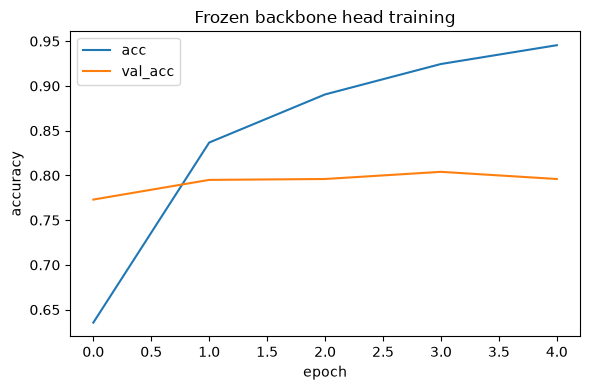

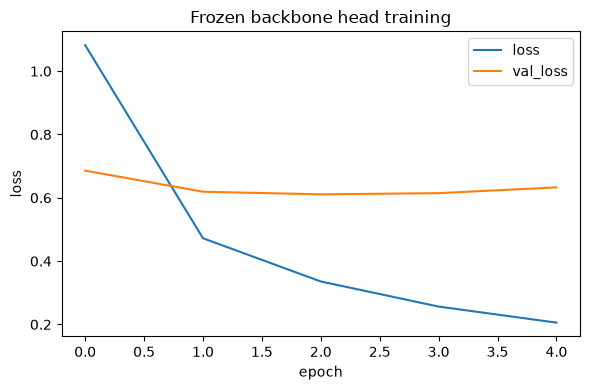

{'frozen_test_acc': 0.817, 'train_time_s': 69.7}


In [15]:
# PREFILLED: just execute
IMG_FE = (160,160)
base = tf.keras.applications.MobileNetV2(input_shape=(IMG_FE[0], IMG_FE[1], 3),
                                         include_top=False, weights="imagenet")
base.trainable = False
preproc = tf.keras.applications.mobilenet_v2.preprocess_input

def build_head(num_classes=10):
    inputs = layers.Input(shape=(32,32,3))
    x = layers.Resizing(*IMG_FE)(inputs)    # was tf.image.resize(inputs, IMG_FE), which fails in Keras 3
    x = preproc(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return models.Model(inputs, outputs)

from tensorflow.keras.datasets import cifar10
(x_tr, y_tr), (x_te, y_te) = cifar10.load_data()
y_tr = y_tr.ravel(); y_te = y_te.ravel()
# my change: fixed subsets so it runs on a CPU
tr_idx = np.random.RandomState(1).choice(len(x_tr), 5000, replace=False)
te_idx = np.random.RandomState(2).choice(len(x_te), 2000, replace=False)
x_tr, y_tr = x_tr[tr_idx], y_tr[tr_idx]
x_te, y_te = x_te[te_idx], y_te[te_idx]

tf.keras.utils.set_random_seed(42)
model_frozen = build_head(10)
model_frozen.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
hist_frozen = model_frozen.fit(x_tr, y_tr, epochs=5, batch_size=128, validation_split=0.2, verbose=2)
t_frozen = time.time() - t0
plot_history(hist_frozen, title="Frozen backbone head training")
acc_frozen = float(model_frozen.evaluate(x_te, y_te, verbose=0)[1])
print({"frozen_test_acc": round(acc_frozen, 4), "train_time_s": round(t_frozen, 1)})

### 3.2 Fine tune

**To-Do:** Unfreeze the top N layers of the backbone. Use a lower learning rate. Train for a few more epochs. Compare accuracy to the frozen model and to a scratch model.

The template line `model_ft.layers[3] = base` can't work (Keras layers can't be swapped that way), and a rebuilt head would start from random weights. So I do it like this: `build_head` already uses the same `base` object, and I copy all the trained weights from the frozen model into `model_ft`. Before every learning-rate run I reset to those weights, so each run starts from the same point. Note that `model_frozen` and `model_ft` share `base`, so I saved the frozen test accuracy above before fine-tuning.

trainable weights in the base: 41
Epoch 1/3


32/32 - 20s - 619ms/step - accuracy: 0.7815 - loss: 0.7099 - val_accuracy: 0.2700 - val_loss: 4.3506


Epoch 2/3


32/32 - 15s - 480ms/step - accuracy: 0.9377 - loss: 0.1869 - val_accuracy: 0.2330 - val_loss: 6.1952


Epoch 3/3


32/32 - 14s - 437ms/step - accuracy: 0.9793 - loss: 0.0636 - val_accuracy: 0.3900 - val_loss: 3.4229


... (3 outputs left out)

32/32 - 12s - 389ms/step - accuracy: 0.9870 - loss: 0.0758 - val_accuracy: 0.7990 - val_loss: 0.7472


Epoch 3/3


32/32 - 15s - 483ms/step - accuracy: 1.0000 - loss: 0.0242 - val_accuracy: 0.8060 - val_loss: 0.7371


0.0001 (0.8305000066757202, 53.975894927978516)


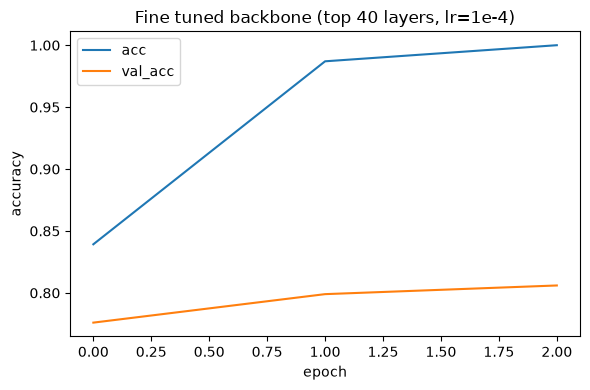

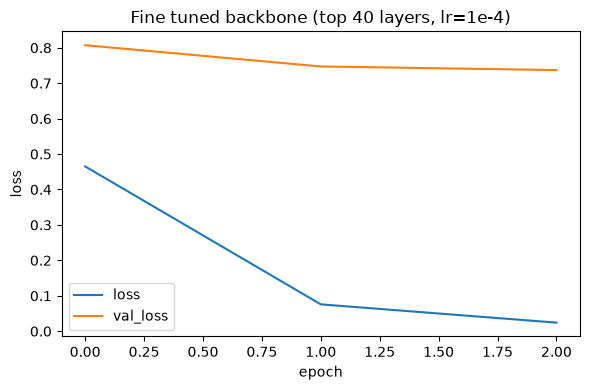

Epoch 1/3


32/32 - 20s - 629ms/step - accuracy: 0.7498 - loss: 0.7011 - val_accuracy: 0.8060 - val_loss: 0.6453


Epoch 2/3


32/32 - 12s - 363ms/step - accuracy: 0.8512 - loss: 0.4508 - val_accuracy: 0.7990 - val_loss: 0.6574


Epoch 3/3


32/32 - 13s - 400ms/step - accuracy: 0.8938 - loss: 0.3493 - val_accuracy: 0.8020 - val_loss: 0.6589


1e-05 (0.8144999742507935, 49.06487822532654)


In [16]:
# To-Do: unfreeze and fine tune
w_frozen = model_frozen.get_weights()           # starting point for every fine-tuning run
base.trainable = True
for l in base.layers[:-40]:
    l.trainable = False                          # only the top 40 layers can change
model_ft = build_head(10)  # rebuild to attach the now-trainable base
print("trainable weights in the base:", len(base.trainable_weights))

ft_results = {}
for lr in [1e-3, 1e-4, 1e-5]:
    model_ft.set_weights(w_frozen)               # same start for each learning rate
    model_ft.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    hist_ft = model_ft.fit(x_tr, y_tr, epochs=3, batch_size=128, validation_split=0.2, verbose=2)
    ft_results[f"top 40 layers, lr={lr:g}"] = (float(model_ft.evaluate(x_te, y_te, verbose=0)[1]), time.time() - t0)
    print(lr, ft_results[f"top 40 layers, lr={lr:g}"])
    if lr == 1e-4:
        plot_history(hist_ft, title="Fine tuned backbone (top 40 layers, lr=1e-4)")

In [17]:
# fine-tuning ALL layers with the smallest learning rate, for comparison
for l in base.layers:
    l.trainable = True                           # every layer of MobileNetV2 can change now
print("trainable weights in the base:", len(base.trainable_weights))
model_ft.set_weights(w_frozen)
model_ft.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
h_all = model_ft.fit(x_tr, y_tr, epochs=3, batch_size=128, validation_split=0.2, verbose=2)
ft_results["all layers, lr=1e-05"] = (float(model_ft.evaluate(x_te, y_te, verbose=0)[1]), time.time() - t0)
print(ft_results["all layers, lr=1e-05"])

trainable weights in the base: 156
Epoch 1/3


32/32 - 58s - 2s/step - accuracy: 0.6500 - loss: 1.0538 - val_accuracy: 0.8120 - val_loss: 0.6205


Epoch 2/3


32/32 - 43s - 1s/step - accuracy: 0.7768 - loss: 0.6651 - val_accuracy: 0.8060 - val_loss: 0.6150


Epoch 3/3


32/32 - 85s - 3s/step - accuracy: 0.8407 - loss: 0.4967 - val_accuracy: 0.8130 - val_loss: 0.6105


(0.8234999775886536, 224.46756386756897)


In [18]:
# a CNN from scratch on the same 5,000 images (cheap epochs, so it gets 20)
tf.keras.utils.set_random_seed(42)
inp = layers.Input(shape=(32, 32, 3))
x = layers.Rescaling(1./255)(inp)
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
model_scratch = models.Model(inp, layers.Dense(10, activation="softmax")(x))
model_scratch.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
h_scratch = model_scratch.fit(x_tr, y_tr, epochs=20, batch_size=128, validation_split=0.2, verbose=0)
t_scratch = time.time() - t0

summary = {"frozen base, 5 epochs": (acc_frozen, t_frozen)}
summary.update(ft_results)
summary["from scratch, 20 epochs"] = (float(model_scratch.evaluate(x_te, y_te, verbose=0)[1]), t_scratch)
for k, (a, t) in summary.items():
    print(f"{k:28s} test acc: {a:.4f}   train time: {t:6.1f} s")

frozen base, 5 epochs        test acc: 0.8170   train time:   69.7 s
top 40 layers, lr=0.001      test acc: 0.3825   train time:   53.6 s
top 40 layers, lr=0.0001     test acc: 0.8305   train time:   54.0 s
top 40 layers, lr=1e-05      test acc: 0.8145   train time:   49.1 s
all layers, lr=1e-05         test acc: 0.8235   train time:  224.5 s
from scratch, 20 epochs      test acc: 0.5925   train time:   11.1 s


**What I see:** All runs use the same 4,000 training images and the same 2,000 test images. The **frozen backbone** reached **81.7%** in 5 epochs (70 s). Fine-tuning the **top 40 layers** started from those weights each time, and the learning rate decided everything. With **lr = 1e-3** validation accuracy collapsed to 27% after the first epoch and ended at **38.3%**: the large steps destroyed the pre-trained features. **lr = 1e-4** gave the best result, **83.1% (+1.4 points)**, although training accuracy hit 100%, so it is already overfitting 4,000 images. **lr = 1e-5** barely moved in 3 epochs (81.5%). Fine-tuning **all layers** at 1e-5 reached 82.4%, slightly better than the top 40 at the same rate, but it took **4.5 times longer** (224 s vs about 50 s). The **scratch CNN** got only **59.3%** after 20 epochs, though in just 11 s. With this little data, I'd freeze the base, train the head, then fine-tune only the top layers with a learning rate around 1e-4. Fine-tuning everything costs a lot more for a small gain, and with 2,000 test images a difference of about 1 point is close to noise.

**Learning point**  
Freeze then fine tune is stable and efficient. Use a lower learning rate for the backbone than for the head to avoid destroying pre trained features.

# Exercise 4: Model interpretability

**As stated in the exercises**  
Train a CNN and understand which regions drive predictions. Use Grad CAM and optionally LIME. Visualize attention maps and reason about relevance and bias.

### 4.1 Grad CAM helper

**PREFILLED**  
The function below computes Grad CAM for a given image and class index for models with a final conv layer.

In [19]:
# PREFILLED: just execute
def grad_cam(model, img, class_index, layer_name=None):
    if layer_name is None:
        # find last conv layer
        for l in reversed(model.layers):
            if isinstance(l, layers.Conv2D):
                layer_name = l.name
                break
    conv_layer = model.get_layer(layer_name)
    grad_model = tf.keras.models.Model([model.inputs], [conv_layer.output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(tf.expand_dims(img, 0))
        loss = preds[:, class_index]
    grads = tape.gradient(loss, conv_out)
    weights = tf.reduce_mean(grads, axis=(0,1,2))
    cam = tf.reduce_sum(tf.multiply(weights, conv_out[0]), axis=-1)
    cam = tf.maximum(cam, 0) / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], img.shape[:2])
    return cam.numpy().squeeze()

def overlay_cam(img, cam, alpha=0.4):
    plt.figure(figsize=(4,4))
    plt.imshow(img.astype("uint8"))
    plt.imshow(cam, cmap="jet", alpha=alpha)
    plt.axis("off"); plt.tight_layout(); plt.show()

### 4.2 Run Grad CAM

**To-Do:** Choose a trained model and a few sample images. Generate Grad CAM maps for the predicted class. Inspect whether highlighted regions correspond to the object. Document your findings.

For Grad-CAM I need a model whose layers include its conv layers directly (the prefilled `grad_cam` looks for the last `Conv2D` in `model.layers`, so it can't see inside the MobileNetV2 block). The Exercise 3 scratch model only saw 4,000 images, so I train the same kind of functional CNN on all 50,000 CIFAR-10 images for 8 epochs. That gives better maps. Its last conv layer works at 8x8, so each heatmap cell covers 4x4 pixels of the 32x32 image.

In [20]:
# a CNN trained on all of CIFAR-10 to explain
(xg_tr, yg_tr), (xg_te, yg_te) = cifar10.load_data()
yg_tr = yg_tr.ravel(); yg_te = yg_te.ravel()
tf.keras.utils.set_random_seed(42)
inp = layers.Input(shape=(32, 32, 3))
x = layers.Rescaling(1./255)(inp)
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(128, 3, padding="same", activation="relu", name="last_conv")(x)   # 8x8 maps
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
model_gc = models.Model(inp, layers.Dense(10, activation="softmax")(x))
model_gc.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_gc.fit(xg_tr, yg_tr, epochs=8, batch_size=128, validation_split=0.1, verbose=2)
print("test accuracy:", round(float(model_gc.evaluate(xg_te, yg_te, verbose=0)[1]), 4))

Epoch 1/8


352/352 - 10s - 29ms/step - accuracy: 0.2753 - loss: 1.8815 - val_accuracy: 0.4090 - val_loss: 1.6217


Epoch 2/8


352/352 - 8s - 23ms/step - accuracy: 0.4322 - loss: 1.5334 - val_accuracy: 0.5024 - val_loss: 1.3616


Epoch 3/8


352/352 - 9s - 25ms/step - accuracy: 0.5082 - loss: 1.3474 - val_accuracy: 0.5478 - val_loss: 1.2321


... (7 outputs left out)

352/352 - 117s - 333ms/step - accuracy: 0.6271 - loss: 1.0425 - val_accuracy: 0.6560 - val_loss: 0.9544


Epoch 8/8


352/352 - 10s - 28ms/step - accuracy: 0.6468 - loss: 0.9935 - val_accuracy: 0.6642 - val_loss: 0.9481


test accuracy: 0.6495


true: cat | predicted: cat


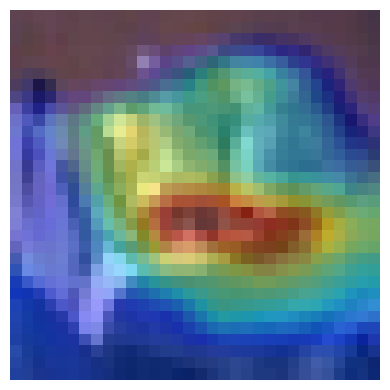

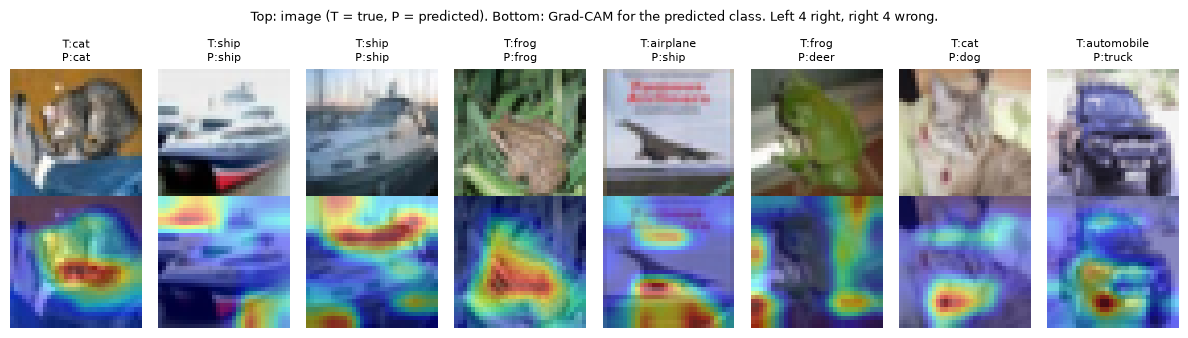

In [21]:
# To-Do: pick a model and sample images, then visualize Grad CAM
img = xg_te[0]  # example
pred = int(np.argmax(model_gc.predict(img[None], verbose=0)[0]))
cam = grad_cam(model_gc, img.astype("float32"), pred)
print("true:", class_names_c10[yg_te[0]], "| predicted:", class_names_c10[pred])
overlay_cam(img, cam)

# a grid: 4 correct and 4 wrong predictions
probs_gc = model_gc.predict(xg_te[:500], verbose=0)
pred_gc = probs_gc.argmax(axis=1)
right = np.where(pred_gc == yg_te[:500])[0][:4]
wrong = np.where(pred_gc != yg_te[:500])[0][:4]
gc_samples = list(right) + list(wrong)
plt.figure(figsize=(12, 3.4))
for j, k in enumerate(gc_samples):
    cam_k = grad_cam(model_gc, xg_te[k].astype("float32"), int(pred_gc[k]))
    plt.subplot(2, 8, j + 1); plt.imshow(xg_te[k]); plt.axis("off")
    plt.title(f"T:{class_names_c10[yg_te[k]]}\nP:{class_names_c10[pred_gc[k]]}", fontsize=8)
    plt.subplot(2, 8, j + 9); plt.imshow(xg_te[k]); plt.imshow(cam_k, cmap="jet", alpha=0.45); plt.axis("off")
plt.suptitle("Top: image (T = true, P = predicted). Bottom: Grad-CAM for the predicted class. Left 4 right, right 4 wrong.", fontsize=9)
plt.tight_layout(); plt.show()

**LIME.** LIME splits the image into small regions (superpixels), hides random groups of them, and checks how the prediction changes. The regions that keep the prediction alive are the important ones. It works with any model, but it needs hundreds of predictions per image. I use the same 8 images as above.

In [22]:
# install LIME if it's missing (it is not preinstalled in Colab)
try:
    from lime import lime_image
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lime"], check=False)
    try:
        from lime import lime_image
    except ImportError:
        lime_image = None
        print("LIME could not be installed here, so I only use Grad-CAM.")

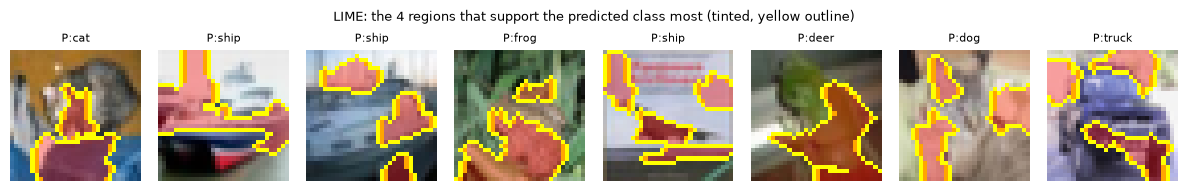

In [23]:
if lime_image is not None:
    from lime.wrappers.scikit_image import SegmentationAlgorithm
    from skimage.segmentation import mark_boundaries
    explainer = lime_image.LimeImageExplainer(random_state=42)
    seg = SegmentationAlgorithm("slic", n_segments=30, compactness=10, start_label=0)  # about 20 regions per 32x32 image
    predict_fn = lambda imgs: model_gc.predict(np.array(imgs), verbose=0)
    plt.figure(figsize=(12, 1.9))
    for j, k in enumerate(gc_samples):
        exp = explainer.explain_instance(xg_te[k].astype("double"), predict_fn, top_labels=1,
                                         hide_color=0, num_samples=400, segmentation_fn=seg)
        temp, mask = exp.get_image_and_mask(exp.top_labels[0], positive_only=True, num_features=4, hide_rest=False)
        plt.subplot(1, 8, j + 1)
        plt.imshow(mark_boundaries(xg_te[k] / 255.0, mask, color=(1, 1, 0)))
        plt.imshow(np.ma.masked_where(mask == 0, mask), cmap="autumn", alpha=0.35)   # tint the chosen regions
        plt.title(f"P:{class_names_c10[exp.top_labels[0]]}", fontsize=8); plt.axis("off")
    plt.suptitle("LIME: the 4 regions that support the predicted class most (tinted, yellow outline)", fontsize=9)
    plt.tight_layout(); plt.show()

**What I see:** The explained CNN reaches 65.0% test accuracy after 8 epochs. For the **correct** predictions, Grad-CAM mostly lands on the object: the cat's body and face, the frog's body, and the hulls of the ships (with some heat on the water and sky around them). The **wrong** predictions are more interesting. For the airplane predicted as *ship*, the heat sits on the flat area at the bottom of the image, not on the plane, so the model seems to have learned "flat area at the bottom = water = ship". That is a background bias. For the frog predicted as *deer*, the heat is on the background around the frog, not the frog itself. For cat → dog and automobile → truck the heat is on the right object, and the mistake comes from the two classes looking alike. LIME mostly agrees: for the cat and the frog it marks regions on the animal, and for the airplane → ship it also picks the bottom strip. Both methods are coarse here. Grad-CAM works on an 8x8 grid, LIME uses about 20 superpixels, and LIME's result depends on random sampling. To fix what this shows, I would add images with varied backgrounds (for example planes over the sea and ships against the sky), use stronger crop and shift augmentation, or train at a higher resolution so the model has object detail to use instead of the background.

**Learning point**  
Grad CAM uses gradients of the target class flowing into the final conv layer to produce a heatmap. It helps verify that the network attends to object regions rather than background artifacts.

![image.png](https://github.com/user-attachments/assets/879a3523-8d3a-42ed-8481-5957021937e9)

# Exercise 5: Building a robust classification pipeline

**As stated in the exercises**  
Create a complete pipeline for image classification including data loading, augmentation, training, evaluation, and saving. Optionally build a simple interface for predictions. Make the pipeline modular and robust.

### 5.1 Data module

**PREFILLED**  
A reusable loader using `image_dataset_from_directory`. It supports train and validation splits.

In [24]:
# PREFILLED: just execute
def load_folder_dataset(root, img_size=(160,160), batch=32, val_split=0.2, seed=42):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        root, validation_split=val_split, subset="training", seed=seed,
        image_size=img_size, batch_size=batch, label_mode="int"
    )
    val_ds = tf.keras.utils.image_dataset_from_directory(
        root, validation_split=val_split, subset="validation", seed=seed,
        image_size=img_size, batch_size=batch, label_mode="int"
    )
    class_names = train_ds.class_names
    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = train_ds.cache().prefetch(AUTOTUNE)
    val_ds = val_ds.cache().prefetch(AUTOTUNE)
    return train_ds, val_ds, class_names

**Getting a folder dataset.** `load_folder_dataset` needs one sub-folder per class. I use the TensorFlow flower photos (3,670 photos, 5 classes: daisy, dandelion, roses, sunflowers, tulips), which come in exactly that layout and download in a few seconds. The function finds the class folders itself, because different Keras versions unpack the archive to slightly different paths.

In [25]:
def get_flowers():
    # download once and return the folder that holds the 5 class folders
    path = tf.keras.utils.get_file("flower_photos",
        origin="https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz", untar=True)
    for root, dirs, _ in os.walk(path):
        if "daisy" in dirs:
            return root
    raise FileNotFoundError("Could not find the flower class folders after download")

DATA_ROOT = get_flowers()
print(DATA_ROOT, sorted(d for d in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, d))))

/home/box/.keras/datasets/flower_photos/flower_photos ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


### 5.2 Model factory

**To-Do:** Implement a model factory that can return a baseline CNN or a MobileNetV2 transfer model based on a string name. Use sensible defaults and allow passing the number of classes.

In [26]:
# To-Do: implement model factory
def make_augmenter():
    # light augmentation, only active during training
    return tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.05),
                                layers.RandomZoom(0.1)], name="augment")

def make_model(kind, num_classes, img_size=(160,160), augment=True):
    if not isinstance(num_classes, int) or num_classes < 2:
        raise ValueError("num_classes must be an int >= 2")
    inputs = layers.Input(shape=(img_size[0], img_size[1], 3))
    x = make_augmenter()(inputs) if augment else inputs
    if kind == "baseline":
        x = layers.Rescaling(1./255)(x)
        for filters in [32, 64, 128]:
            x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
            x = layers.MaxPooling2D()(x)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(0.3)(x)
        outputs = layers.Dense(num_classes, activation="softmax")(x)
    elif kind == "mobilenetv2":
        base = tf.keras.applications.MobileNetV2(input_shape=(img_size[0], img_size[1], 3),
                                                 include_top=False, weights="imagenet")
        base.trainable = False
        preproc = tf.keras.applications.mobilenet_v2.preprocess_input
        x = preproc(x)
        x = base(x, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dense(128, activation="relu")(x)
        outputs = layers.Dense(num_classes, activation="softmax")(x)
    else:
        raise ValueError(f"Unknown kind '{kind}', use 'baseline' or 'mobilenetv2'")
    m = models.Model(inputs, outputs, name=kind)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

# quick check that both kinds build, and that a wrong name fails clearly
for k in ["baseline", "mobilenetv2"]:
    print(k, "parameters:", make_model(k, num_classes=5).count_params())
try:
    make_model("resnet9000", 5)
except ValueError as e:
    print("error as expected:", e)

baseline parameters: 93893


mobilenetv2 parameters: 2422597
error as expected: Unknown kind 'resnet9000', use 'baseline' or 'mobilenetv2'


### 5.3 Training, evaluation, saving

**To-Do:** Train a selected model on a folder dataset. Evaluate on validation data. Save the model and class names to disk and reload them for a test prediction. Add simple error handling for unknown inputs.

Found 3670 files belonging to 5 classes.


Using 2936 files for training.


Found 3670 files belonging to 5 classes.


Using 734 files for validation.


Epoch 1/5


92/92 - 12s - 131ms/step - accuracy: 0.7939 - loss: 0.5661 - val_accuracy: 0.8420 - val_loss: 0.4207


... (4 outputs left out)

Epoch 4/5


92/92 - 7s - 78ms/step - accuracy: 0.9418 - loss: 0.1685 - val_accuracy: 0.8638 - val_loss: 0.4154


              precision    recall  f1-score   support

       daisy      0.882     0.907     0.894       107
   dandelion      0.925     0.901     0.912       191
       roses      0.726     0.958     0.826       119
  sunflowers      0.871     0.896     0.883       135
      tulips      0.958     0.747     0.840       182

    accuracy                          0.872       734
   macro avg      0.872     0.882     0.871       734
weighted avg      0.884     0.872     0.872       734



{'val_accuracy': 0.8719, 'pipeline_time_s': 36.3, 'saved': 'data/robust_cnn.keras'}


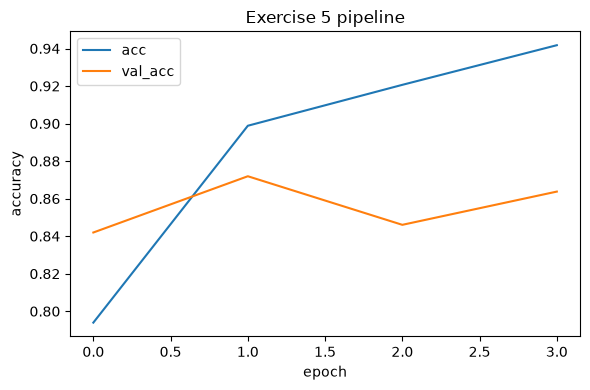

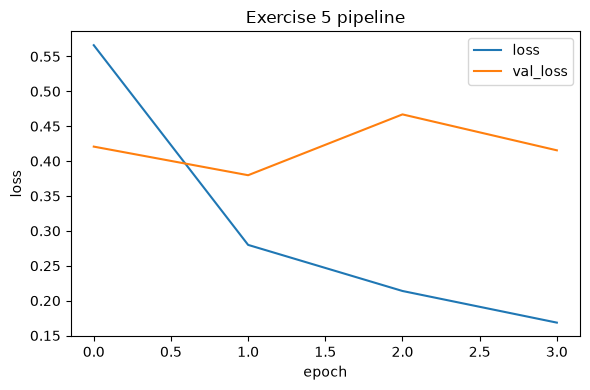

In [27]:
# the rest of the pipeline: train, evaluate, save, load, predict with input checks
from sklearn.metrics import classification_report
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

def train_model(model, train_ds, val_ds, epochs=5):
    cb = [tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cb, verbose=2)

def evaluate_model(model, ds, class_names):
    y_true = np.concatenate([y.numpy() for _, y in ds])
    y_pred = model.predict(ds, verbose=0).argmax(axis=1)
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    return float((y_true == y_pred).mean())

def save_artifacts(model, class_names, out_dir="./data", name="robust_cnn"):
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    model.save(out / f"{name}.keras")                          # Keras 3 needs the .keras extension
    json.dump(class_names, open(out / f"{name}_classes.json", "w"))
    return out / f"{name}.keras", out / f"{name}_classes.json"

def load_artifacts(model_path, classes_path):
    return tf.keras.models.load_model(model_path), json.load(open(classes_path))

def predict_image(model, class_names, path, img_size=(160,160)):
    # returns (label, confidence), or raises ValueError with a clear message for bad input
    p = Path(path)
    if not p.is_file():
        raise ValueError(f"File not found: {path}")
    if p.suffix.lower() not in IMG_EXT:
        raise ValueError(f"Not an image file type: {p.suffix}")
    try:
        im = load_image(str(p), size=img_size).numpy()          # from the Exercise 1 setup; gives 0..1, RGB
    except tf.errors.InvalidArgumentError:
        raise ValueError(f"Could not decode image: {path}")
    pr = model.predict(im[None] * 255.0, verbose=0)[0]           # the model was trained on 0..255 pixels
    return class_names[int(np.argmax(pr))], float(np.max(pr))

def run_pipeline(root, kind="mobilenetv2", img_size=(160,160), epochs=5, out_dir="./data"):
    tf.keras.utils.set_random_seed(42)
    train_ds, val_ds, class_names = load_folder_dataset(root, img_size=img_size)
    model = make_model(kind, num_classes=len(class_names), img_size=img_size)
    hist = train_model(model, train_ds, val_ds, epochs=epochs)
    acc = evaluate_model(model, val_ds, class_names)
    paths = save_artifacts(model, class_names, out_dir)
    return model, class_names, hist, acc, paths

t0 = time.time()
model_p, class_names_p, hist_p, acc_p, (model_path, classes_path) = run_pipeline(DATA_ROOT, epochs=5)
print({"val_accuracy": round(acc_p, 4), "pipeline_time_s": round(time.time() - t0, 1), "saved": str(model_path)})
plot_history(hist_p, title="Exercise 5 pipeline")

In [28]:
# reload from disk and test the input checks
m2, classes = load_artifacts(model_path, classes_path)
sample = next(Path(DATA_ROOT, "roses").glob("*.jpg"))
print("good image ->", predict_image(m2, classes, sample))

# a grayscale PNG still works, because load_image always decodes to 3 channels
gray_path = Path("./data/gray_test.png")
tf.io.write_file(str(gray_path), tf.io.encode_png(tf.image.rgb_to_grayscale(tf.io.decode_jpeg(tf.io.read_file(str(sample))))))
print("grayscale image ->", predict_image(m2, classes, gray_path))

bad_text = Path("./data/not_an_image.jpg"); bad_text.write_text("hello")
for bad in ["./data/missing.jpg", str(classes_path), str(bad_text)]:
    try:
        predict_image(m2, classes, bad)
    except ValueError as e:
        print("rejected ->", e)

good image -> ('roses', 0.9869893193244934)
grayscale image -> ('roses', 0.9855400919914246)
rejected -> File not found: ./data/missing.jpg
rejected -> Not an image file type: .json
rejected -> Could not decode image: data/not_an_image.jpg


**What I see:** The pipeline is split into small functions, each doing one job: `get_flowers` / `load_folder_dataset` (data), `make_augmenter` + `make_model` (model factory, `baseline` or `mobilenetv2`), `train_model`, `evaluate_model`, `save_artifacts` / `load_artifacts`, and `predict_image`. `run_pipeline` chains them, so another dataset or model only needs a new folder path or a new branch in `make_model`. On the 5 class flower photos (2,936 train / 734 validation) the frozen MobileNetV2 with augmentation reached **87.2% validation accuracy**. Early stopping ended training after 4 epochs and kept epoch 2. The weakest class is **tulips** (recall 74.7%), which are mostly confused with roses (roses precision 72.6%). The whole run took 36 s on the CPU. The model and its class list are saved together (`.keras` + JSON), and the reloaded model predicted *roses* at 98.7% for a rose photo. For robustness, a grayscale PNG still works (it is decoded to 3 channels), and a missing file, a non-image file type and a broken file are rejected with clear messages instead of crashing. I also fixed two template problems: Keras 3 needs the `.keras` extension when saving, and `load_image` returns pixels in 0..1 while the model was trained on 0..255, so I multiply by 255 before predicting (without this, every prediction would quietly be wrong). For version control, I keep the code in Git and keep `./data` (models and downloads) out of the repo. I skipped the optional UI; a small Gradio app calling `predict_image` would be the easy next step.

**Learning point**  
A robust pipeline is modular and testable. Keep data loading, modeling, and evaluation separate. Save models with their label maps. Validate inputs and fail safely.